# Room B — Multi-Receiver CSI Occupancy Detection

This notebook adapts the supplied occupancy-classification workflow to the fused ESP32 dataset.

**Label definition confirmed for this experiment**
- `C1 = 0` → Empty
- `C2` through `C8 = 1` → Occupied

**Input layout expected inside `RoomB_FUSED.zip`:**
```text
RoomB_FUSED/
  C1/Rep01/Fused_window_summary.csv
  ...
  C8/Rep08/Fused_window_summary.csv
```

**Experiments**
1. RX1-only features
2. RX2-only features
3. Fused RX1 + RX2 features

Each experiment compares CSI-only, RSSI-only, and combined CSI/RSSI/amplitude/packet-count feature sets. Models: Logistic Regression, Random Forest, and RBF-SVM. Class balancing: class weighting and training-only undersampling.

**Important:** The input CSVs are per-second window summaries. This notebook does not reconstruct raw packet-level CSI or I/Q samples. Five-second feature windows are formed using the actual `second` values, not row position, so a missing second cannot silently shift the window boundaries.


## 1. Environment and imports

The notebook is designed to run in Google Colab or a local Jupyter environment. In Colab, upload `RoomB_FUSED.zip` when prompted.


In [ ]:
import re
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

RANDOM_STATE = 42
WINDOW_SIZE = 5

# Repetition-level split: all windows from a repetition stay in one split.
TRAIN_REPS = [f"Rep{i:02d}" for i in range(1, 6)]
VAL_REPS = ["Rep06"]
TEST_REPS = ["Rep07", "Rep08"]

CASE_LABELS = {
    "C1": 0,
    "C2": 1,
    "C3": 1,
    "C4": 1,
    "C5": 1,
    "C6": 1,
    "C7": 1,
    "C8": 1,
}
OCCUPIED_CASES = [f"C{i}" for i in range(2, 9)]

# Same active subcarrier selection as the supplied script:
# subcarriers 01-26 and 38-63 (52 total).
ACTIVE_INDICES = list(range(1, 27)) + list(range(38, 64))
SUBCARRIER_COLS = [f"subcarrier_{i:02d}" for i in ACTIVE_INDICES]

BASE_DIR = Path("/content") if Path("/content").exists() else Path.cwd()
ZIP_PATH = BASE_DIR / "RoomB_FUSED.zip"
EXTRACT_DIR = BASE_DIR / "RoomB_FUSED_INPUT"
OUTPUT_DIR = BASE_DIR / "RoomB_Analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", BASE_DIR)
print("Output directory:", OUTPUT_DIR)
print("Active subcarriers:", len(SUBCARRIER_COLS))


Working directory: /content
Output directory: /content/RoomB_Analysis
Active subcarriers: 52


## 2. Upload and extract the fused dataset

Upload the ZIP created from the 64 fused files. The extraction code checks for the expected `RoomB_FUSED/Cx/RepXX/Fused_window_summary.csv` structure.


In [ ]:
if not ZIP_PATH.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        zip_candidates = [name for name in uploaded if name.lower().endswith(".zip")]
        if not zip_candidates:
            raise FileNotFoundError("Please upload RoomB_FUSED.zip.")
        ZIP_PATH = Path(zip_candidates[0])
    except ImportError:
        raise FileNotFoundError(
            f"Place RoomB_FUSED.zip in {BASE_DIR} or set ZIP_PATH to its location."
        )

if EXTRACT_DIR.exists():
    import shutil
    shutil.rmtree(EXTRACT_DIR)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    bad_member = zf.testzip()
    if bad_member:
        raise RuntimeError(f"ZIP integrity check failed at: {bad_member}")
    zf.extractall(EXTRACT_DIR)


candidate_roots = list(EXTRACT_DIR.rglob("RoomB_FUSED"))
if candidate_roots:
    DATA_ROOT = candidate_roots[0]
else:
    candidate_files = list(EXTRACT_DIR.glob("C*/Rep*/Fused_window_summary.csv"))
    if candidate_files:
        DATA_ROOT = EXTRACT_DIR
    else:
        raise FileNotFoundError("Could not find the RoomB_FUSED scenario/repetition structure.")

print("Dataset root:", DATA_ROOT)


Saving RoomB_FUSED.zip to RoomB_FUSED.zip
Dataset root: /content/RoomB_FUSED_INPUT/RoomB_FUSED


## 3. Inspect all 64 recordings and validate columns

The fusion CSVs should contain a common `second` column, receiver-specific feature columns (`RX1_...`, `RX2_...`), and receiver-presence indicators. This cell reports missing files, duplicate seconds, missing required features, and recording lengths before feature extraction.


In [ ]:
recording_paths = {}
inspection_rows = []

for case in CASE_LABELS:
    for rep in [f"Rep{i:02d}" for i in range(1, 9)]:
        path = DATA_ROOT / case / rep / "Fused_window_summary.csv"
        if not path.exists():
            inspection_rows.append({
                "case": case, "repetition": rep, "status": "MISSING_FILE"
            })
            continue

        df = pd.read_csv(path)
        recording_paths[(case, rep)] = path

        row = {
            "case": case,
            "repetition": rep,
            "status": "OK",
            "rows": len(df),
            "columns": len(df.columns),
            "duplicate_seconds": int(df["second"].duplicated().sum()) if "second" in df else None,
            "min_second": df["second"].min() if "second" in df else None,
            "max_second": df["second"].max() if "second" in df else None,
            "missing_cells": int(df.isna().sum().sum()),
        }

        for rx in ["RX1", "RX2"]:
            row[f"{rx}_present_rows"] = (
                int(df[f"{rx}_record_present"].fillna(False).astype(bool).sum())
                if f"{rx}_record_present" in df else None
            )
        inspection_rows.append(row)

inspection = pd.DataFrame(inspection_rows)
display(inspection)

print("Files found:", len(recording_paths), "/ 64")
if len(recording_paths) != 64:
    warnings.warn("Not all 64 recordings were found. Check the extracted directory structure.")

if inspection["status"].eq("MISSING_FILE").any():
    raise FileNotFoundError("At least one expected recording is missing. Resolve before proceeding.")

for key, path in recording_paths.items():
    df = pd.read_csv(path)
    if "second" not in df.columns:
        raise ValueError(f"'second' column missing: {path}")
    if df["second"].duplicated().any():
        raise ValueError(f"Duplicate second values: {path}")

    for rx in ["RX1", "RX2"]:
        required = [f"{rx}_{c}" for c in SUBCARRIER_COLS]
        required += [
            f"{rx}_mean_rssi", f"{rx}_std_rssi",
            f"{rx}_mean_csi_amplitude", f"{rx}_std_csi_amplitude",
            f"{rx}_packet_count", f"{rx}_record_present"
        ]
        missing = [c for c in required if c not in df.columns]
        if missing:
            raise ValueError(f"{path.name} missing {rx} columns: {missing[:10]}")

print("Structural validation passed.")


,case,repetition,status,rows,columns,duplicate_seconds,min_second,max_second,missing_cells,RX1_present_rows,RX2_present_rows
0,C1,Rep01,OK,120,141,0,0,119,6,120,120
1,C1,Rep02,OK,120,141,0,0,119,10,120,120
2,C1,Rep03,OK,120,141,0,0,119,16,120,120
3,C1,Rep04,OK,120,141,0,0,119,12,120,120
4,C1,Rep05,OK,120,141,0,0,119,0,120,120
...,...,...,...,...,...,...,...,...,...,...,...
59,C8,Rep04,OK,120,141,0,0,119,26,120,120
60,C8,Rep05,OK,120,141,0,0,119,34,120,120
61,C8,Rep06,OK,120,141,0,0,119,93,120,119
62,C8,Rep07,OK,120,141,0,0,119,164,120,118


Files found: 64 / 64
Structural validation passed.


## 4. Create five-second feature windows

Windows are anchored to the recording's `second` index:
- window 0: seconds 0–4
- window 1: seconds 5–9
- and so on.

For each receiver and window, calculate the same feature families as the supplied code:
- CSI: mean and standard deviation for each selected subcarrier
- RSSI: mean, temporal standard deviation, and mean of per-second RSSI standard deviation
- CSI amplitude: mean and temporal standard deviation
- Packet count: mean

**Missing-window handling:** If a receiver has fewer than five recorded seconds in a five-second interval, its available values are summarized and the number/fraction of observed seconds is recorded. If it has no observations in that interval, its receiver features remain missing. The downstream imputer is fitted on training data only. No missing CSI values are replaced with measured zero values during feature extraction.


In [ ]:
def safe_bool_series(series):
    if series.dtype == bool:
        return series.fillna(False)
    return series.astype(str).str.strip().str.lower().isin(["true", "1", "yes"])


def receiver_window_features(chunk, rx, window_start):
    present_col = f"{rx}_record_present"
    present_mask = safe_bool_series(chunk[present_col])
    observed = chunk.loc[present_mask].copy()

    features = {
        f"{rx.lower()}_observed_seconds": int(len(observed)),
        f"{rx.lower()}_observed_fraction": float(len(observed) / WINDOW_SIZE),
    }

    # No receiver data in this window: leave measurement features missing.
    if observed.empty:
        for col in SUBCARRIER_COLS:
            features[f"{rx}_{col}_mean"] = np.nan
            features[f"{rx}_{col}_std"] = np.nan
        for name in [
            "rssi_mean", "rssi_temporal_std", "rssi_packet_std_mean",
            "csi_amplitude_mean", "csi_amplitude_temporal_std",
            "packet_count_mean"
        ]:
            features[f"{rx}_{name}"] = np.nan
        return features

    numeric_cols = [f"{rx}_{c}" for c in SUBCARRIER_COLS] + [
        f"{rx}_mean_rssi", f"{rx}_std_rssi",
        f"{rx}_mean_csi_amplitude", f"{rx}_std_csi_amplitude",
        f"{rx}_packet_count"
    ]
    observed[numeric_cols] = observed[numeric_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    for col in SUBCARRIER_COLS:
        values = observed[f"{rx}_{col}"]
        features[f"{rx}_{col}_mean"] = values.mean()
        features[f"{rx}_{col}_std"] = values.std(ddof=0)

    rssi = observed[f"{rx}_mean_rssi"]
    features[f"{rx}_rssi_mean"] = rssi.mean()
    features[f"{rx}_rssi_temporal_std"] = rssi.std(ddof=0)
    features[f"{rx}_rssi_packet_std_mean"] = observed[f"{rx}_std_rssi"].mean()

    amp = observed[f"{rx}_mean_csi_amplitude"]
    features[f"{rx}_csi_amplitude_mean"] = amp.mean()
    features[f"{rx}_csi_amplitude_temporal_std"] = amp.std(ddof=0)

    features[f"{rx}_packet_count_mean"] = observed[f"{rx}_packet_count"].mean()
    return features


samples = []

for (case, repetition), path in sorted(recording_paths.items()):
    df = pd.read_csv(path).sort_values("second").copy()
    df["second"] = pd.to_numeric(df["second"], errors="coerce")
    df = df.dropna(subset=["second"])
    df["window_start_second"] = (
        np.floor(df["second"] / WINDOW_SIZE).astype(int) * WINDOW_SIZE
    )

    for window_start, chunk in df.groupby("window_start_second", sort=True):
    
        rx1_present = safe_bool_series(chunk["RX1_record_present"]).any()
        rx2_present = safe_bool_series(chunk["RX2_record_present"]).any()
        if not (rx1_present or rx2_present):
            continue

        row = {
            "case": case,
            "repetition": repetition,
            "label": CASE_LABELS[case],
            "window_start_second": int(window_start),
            "window_end_second": int(window_start + WINDOW_SIZE - 1),
        }
        row.update(receiver_window_features(chunk, "RX1", window_start))
        row.update(receiver_window_features(chunk, "RX2", window_start))
        samples.append(row)

feature_dataset = pd.DataFrame(samples)
if feature_dataset.empty:
    raise RuntimeError("No five-second feature windows were created.")

feature_dataset.to_csv(OUTPUT_DIR / "all_receiver_features.csv", index=False)

print("Total feature windows:", len(feature_dataset))
print("Unique recordings:", feature_dataset[["case", "repetition"]].drop_duplicates().shape[0])
print("Rows per scenario:")
display(feature_dataset.groupby(["case", "label"]).size().rename("windows").reset_index())
display(feature_dataset.head())


Total feature windows: 1536
Unique recordings: 64
Rows per scenario:


,case,label,windows
0,C1,0,192
1,C2,1,192
2,C3,1,192
3,C4,1,192
4,C5,1,192
5,C6,1,192
6,C7,1,192
7,C8,1,192


,case,repetition,label,window_start_second,window_end_second,rx1_observed_seconds,rx1_observed_fraction,RX1_subcarrier_01_mean,RX1_subcarrier_01_std,RX1_subcarrier_02_mean,...,RX2_subcarrier_62_mean,RX2_subcarrier_62_std,RX2_subcarrier_63_mean,RX2_subcarrier_63_std,RX2_rssi_mean,RX2_rssi_temporal_std,RX2_rssi_packet_std_mean,RX2_csi_amplitude_mean,RX2_csi_amplitude_temporal_std,RX2_packet_count_mean
0,C1,Rep01,0,0,4,5,1.0,15.952703,1.050084,15.669794,...,12.190316,1.142744,13.682148,1.192359,-42.652273,0.365591,0.288393,10.154866,0.285659,12.2
1,C1,Rep01,0,5,9,5,1.0,15.176440,0.139073,14.995738,...,12.439341,0.687938,13.860115,0.950921,-42.271429,0.351092,0.180552,10.128120,0.246689,15.0
2,C1,Rep01,0,10,14,5,1.0,14.698267,0.103803,14.500902,...,12.201288,0.413095,13.673165,0.380700,-41.880000,0.193907,0.171103,10.222852,0.196622,9.4
3,C1,Rep01,0,15,19,5,1.0,15.323469,0.227602,15.076225,...,12.286368,0.363987,13.518849,0.441358,-42.000000,0.000000,0.000000,10.269461,0.174009,8.4
4,C1,Rep01,0,20,24,5,1.0,15.137766,0.408826,14.945160,...,12.702138,0.397574,13.682511,0.484585,-41.920000,0.097980,0.171521,10.414347,0.263078,9.4


## 5. Define RX1, RX2, and fused feature configurations

The CSI-only configuration uses the selected 52 subcarriers and their mean/std features. RSSI-only uses three RSSI statistics. Combined uses CSI, RSSI, amplitude, and packet-count features.

The observed-seconds and observed-fraction fields are retained as data-quality features for each receiver. In the fused experiment, they help the model distinguish a genuine low signal from a receiver window with missing observations.


In [ ]:
def feature_lists_for_receiver(rx):
    csi = [
        f"{rx}_{col}_{stat}"
        for col in SUBCARRIER_COLS
        for stat in ["mean", "std"]
    ]
    rssi = [
        f"{rx}_rssi_mean",
        f"{rx}_rssi_temporal_std",
        f"{rx}_rssi_packet_std_mean",
    ]
    extras = [
        f"{rx}_csi_amplitude_mean",
        f"{rx}_csi_amplitude_temporal_std",
        f"{rx}_packet_count_mean",
    ]
    coverage = [
        f"{rx.lower()}_observed_seconds",
        f"{rx.lower()}_observed_fraction",
    ]
    return csi, rssi, extras, coverage


rx1_csi, rx1_rssi, rx1_extra, rx1_coverage = feature_lists_for_receiver("RX1")
rx2_csi, rx2_rssi, rx2_extra, rx2_coverage = feature_lists_for_receiver("RX2")

FEATURE_CONFIGS = {}

# RX1-only conditions
FEATURE_CONFIGS["RX1_CSI_only"] = rx1_csi + rx1_coverage
FEATURE_CONFIGS["RX1_RSSI_only"] = rx1_rssi + rx1_coverage
FEATURE_CONFIGS["RX1_CSI_RSSI_combined"] = rx1_csi + rx1_rssi + rx1_extra + rx1_coverage

# RX2-only conditions
FEATURE_CONFIGS["RX2_CSI_only"] = rx2_csi + rx2_coverage
FEATURE_CONFIGS["RX2_RSSI_only"] = rx2_rssi + rx2_coverage
FEATURE_CONFIGS["RX2_CSI_RSSI_combined"] = rx2_csi + rx2_rssi + rx2_extra + rx2_coverage

# Fused conditions: concatenate both receivers' features; never average RX1 and RX2.
FEATURE_CONFIGS["FUSED_CSI_only"] = rx1_csi + rx2_csi + rx1_coverage + rx2_coverage
FEATURE_CONFIGS["FUSED_RSSI_only"] = rx1_rssi + rx2_rssi + rx1_coverage + rx2_coverage
FEATURE_CONFIGS["FUSED_CSI_RSSI_combined"] = (
    rx1_csi + rx1_rssi + rx1_extra +
    rx2_csi + rx2_rssi + rx2_extra +
    rx1_coverage + rx2_coverage
)

for name, cols in FEATURE_CONFIGS.items():
    missing = [c for c in cols if c not in feature_dataset.columns]
    if missing:
        raise ValueError(f"{name} references missing features: {missing[:10]}")

print("Feature configurations:", len(FEATURE_CONFIGS))
for name, cols in FEATURE_CONFIGS.items():
    print(f"{name:28s}: {len(cols)} features")


Feature configurations: 9
RX1_CSI_only                : 106 features
RX1_RSSI_only               : 5 features
RX1_CSI_RSSI_combined       : 112 features
RX2_CSI_only                : 106 features
RX2_RSSI_only               : 5 features
RX2_CSI_RSSI_combined       : 112 features
FUSED_CSI_only              : 212 features
FUSED_RSSI_only             : 10 features
FUSED_CSI_RSSI_combined     : 224 features


## 6. Verify labels and repetition-level split

C1 is the empty class; C2–C8 are occupied. The split is made by repetition number across all scenarios:
- Train: Rep01–Rep05
- Validation: Rep06
- Test: Rep07–Rep08

Do not randomly split individual five-second windows. Windows from one recording must not be scattered across train, validation, and test.


In [ ]:
print("Class distribution:")
display(feature_dataset["label"].value_counts().sort_index().rename(index={0: "Empty", 1: "Occupied"}))

print("Case-label distribution:")
display(feature_dataset.groupby(["case", "label"]).size().rename("windows").reset_index())

recording_counts = feature_dataset[["case", "repetition"]].drop_duplicates()
print("Unique case-repetition recordings:", len(recording_counts), "/ 64")

train_df = feature_dataset[feature_dataset["repetition"].isin(TRAIN_REPS)].copy()
val_df = feature_dataset[feature_dataset["repetition"].isin(VAL_REPS)].copy()
test_df = feature_dataset[feature_dataset["repetition"].isin(TEST_REPS)].copy()

for split_name, split_df in [("TRAIN", train_df), ("VALIDATION", val_df), ("TEST", test_df)]:
    print(f"\n{split_name}")
    print("Windows:", len(split_df))
    print("Recordings:", split_df[["case", "repetition"]].drop_duplicates().shape[0])
    print("Class counts:")
    print(split_df["label"].value_counts().sort_index())

if train_df["label"].nunique() < 2 or val_df["label"].nunique() < 2 or test_df["label"].nunique() < 2:
    raise ValueError("Each train/validation/test split must contain both classes.")


Class distribution:


,count
label,
Empty,192
Occupied,1344


Case-label distribution:


,case,label,windows
0,C1,0,192
1,C2,1,192
2,C3,1,192
3,C4,1,192
4,C5,1,192
5,C6,1,192
6,C7,1,192
7,C8,1,192


Unique case-repetition recordings: 64 / 64

TRAIN
Windows: 960
Recordings: 40
Class counts:
label
0    120
1    840
Name: count, dtype: int64

VALIDATION
Windows: 192
Recordings: 8
Class counts:
label
0     24
1    168
Name: count, dtype: int64

TEST
Windows: 384
Recordings: 16
Class counts:
label
0     48
1    336
Name: count, dtype: int64


## 7. Training-only class balancing

Two strategies are compared:
1. `Class_weighting`: keep the original training data and use `class_weight='balanced'`.
2. `Undersampling`: keep all empty training windows and sample occupied windows approximately equally from C2–C8.

Validation and test data are never undersampled. The undersampling function checks that both classes and all occupied cases are available.


In [ ]:
def balance_training_data(data):
    empty = data[data["label"] == 0].copy()
    if empty.empty:
        raise ValueError("No empty-class training windows are available for undersampling.")

    selected_occupied = []
    samples_per_case = max(1, len(empty) // len(OCCUPIED_CASES))

    for case in OCCUPIED_CASES:
        case_data = data[(data["case"] == case) & (data["label"] == 1)].copy()
        if case_data.empty:
            warnings.warn(f"No occupied training windows for {case}; skipping it.")
            continue

        n = min(samples_per_case, len(case_data))
        selected_occupied.append(
            case_data.sample(n=n, random_state=RANDOM_STATE)
        )

    if not selected_occupied:
        raise ValueError("No occupied training windows are available for undersampling.")

    balanced_occupied = pd.concat(selected_occupied, ignore_index=True)
    balanced = pd.concat([empty, balanced_occupied], ignore_index=True)

    return balanced.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)


strategies = {
    "Class_weighting": {
        "data": train_df.copy(),
        "class_weight": "balanced",
    },
    "Undersampling": {
        "data": balance_training_data(train_df),
        "class_weight": None,
    },
}

for strategy_name, strategy in strategies.items():
    print(strategy_name)
    print(strategy["data"]["label"].value_counts().sort_index())


Class_weighting
label
0    120
1    840
Name: count, dtype: int64
Undersampling
label
0    120
1    119
Name: count, dtype: int64


## 8. Define models and evaluation helpers

Median imputation and scaling are inside each scikit-learn pipeline. Therefore, imputation values and scaling parameters are learned from training data only. Random Forest does not require scaling; Logistic Regression and SVM do.


In [ ]:
def create_models(class_weight):
    return {
        "LogisticRegression": Pipeline([
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=3000,
                class_weight=class_weight,
                random_state=RANDOM_STATE
            ))
        ]),
        "RandomForest": Pipeline([
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("model", __import__("sklearn").ensemble.RandomForestClassifier(
                n_estimators=300,
                max_depth=None,
                class_weight=class_weight,
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ]),
        "SVM": Pipeline([
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scaler", StandardScaler()),
            ("model", SVC(
                kernel="rbf",
                class_weight=class_weight,
                probability=True,
                random_state=RANDOM_STATE
            ))
        ])
    }


def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_occupied": precision_score(y_true, y_pred, zero_division=0),
        "recall_occupied": recall_score(y_true, y_pred, zero_division=0),
        "f1_occupied": f1_score(y_true, y_pred, zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }


## 9. Train all configurations and select using validation only

For every feature configuration, train each model under both balancing strategies. Select the model/strategy with the highest **validation macro-F1** for that feature configuration. The test set is not used for model selection.

After selection, evaluate the selected model once on the held-out test repetitions. This gives one test result for each of the nine receiver/feature configurations.


In [ ]:
validation_results = []
selected_models = {}

for feature_name, feature_cols in FEATURE_CONFIGS.items():
    X_val = val_df[feature_cols]
    y_val = val_df["label"]

    candidates = []

    for strategy_name, strategy in strategies.items():
        current_train = strategy["data"]
        X_train = current_train[feature_cols]
        y_train = current_train["label"]

        models = create_models(strategy["class_weight"])

        for model_name, model in models.items():
            print(f"Fitting {feature_name} | {strategy_name} | {model_name}")
            model.fit(X_train, y_train)

            val_pred = model.predict(X_val)
            metrics = calculate_metrics(y_val, val_pred)

            result = {
                "feature_config": feature_name,
                "strategy": strategy_name,
                "model": model_name,
                **{f"val_{k}": v for k, v in metrics.items()},
            }
            validation_results.append(result)
            candidates.append((metrics["macro_f1"], model, strategy_name, model_name, feature_cols))

    # Deterministic tie-breaking: retain first candidate with best validation macro-F1.
    best = max(candidates, key=lambda item: item[0])
    selected_models[feature_name] = {
        "model": best[1],
        "strategy": best[2],
        "model_name": best[3],
        "feature_cols": best[4],
        "validation_macro_f1": best[0],
    }

validation_results_df = pd.DataFrame(validation_results).sort_values(
    "val_macro_f1", ascending=False
)
validation_results_df.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)
display(validation_results_df.head(20))

print("Selected model per feature configuration:")
for name, selected in selected_models.items():
    print(name, "->", selected["strategy"], selected["model_name"],
          "validation macro-F1:", round(selected["validation_macro_f1"], 4))


Fitting RX1_CSI_only | Class_weighting | LogisticRegression
Fitting RX1_CSI_only | Class_weighting | RandomForest
Fitting RX1_CSI_only | Class_weighting | SVM
Fitting RX1_CSI_only | Undersampling | LogisticRegression
Fitting RX1_CSI_only | Undersampling | RandomForest
Fitting RX1_CSI_only | Undersampling | SVM
Fitting RX1_RSSI_only | Class_weighting | LogisticRegression
Fitting RX1_RSSI_only | Class_weighting | RandomForest
Fitting RX1_RSSI_only | Class_weighting | SVM
Fitting RX1_RSSI_only | Undersampling | LogisticRegression
Fitting RX1_RSSI_only | Undersampling | RandomForest
Fitting RX1_RSSI_only | Undersampling | SVM
Fitting RX1_CSI_RSSI_combined | Class_weighting | LogisticRegression
Fitting RX1_CSI_RSSI_combined | Class_weighting | RandomForest
Fitting RX1_CSI_RSSI_combined | Class_weighting | SVM
Fitting RX1_CSI_RSSI_combined | Undersampling | LogisticRegression
Fitting RX1_CSI_RSSI_combined | Undersampling | RandomForest
Fitting RX1_CSI_RSSI_combined | Undersampling | SVM
Fitt

,feature_config,strategy,model,val_accuracy,val_precision_occupied,val_recall_occupied,val_f1_occupied,val_macro_f1
0,RX1_CSI_only,Class_weighting,LogisticRegression,1.0,1.0,1.0,1.0,1.0
1,RX1_CSI_only,Class_weighting,RandomForest,1.0,1.0,1.0,1.0,1.0
2,RX1_CSI_only,Class_weighting,SVM,1.0,1.0,1.0,1.0,1.0
3,RX1_CSI_only,Undersampling,LogisticRegression,1.0,1.0,1.0,1.0,1.0
4,RX1_CSI_only,Undersampling,RandomForest,1.0,1.0,1.0,1.0,1.0
5,RX1_CSI_only,Undersampling,SVM,1.0,1.0,1.0,1.0,1.0
12,RX1_CSI_RSSI_combined,Class_weighting,LogisticRegression,1.0,1.0,1.0,1.0,1.0
13,RX1_CSI_RSSI_combined,Class_weighting,RandomForest,1.0,1.0,1.0,1.0,1.0
15,RX1_CSI_RSSI_combined,Undersampling,LogisticRegression,1.0,1.0,1.0,1.0,1.0
19,RX2_CSI_only,Class_weighting,RandomForest,1.0,1.0,1.0,1.0,1.0


Selected model per feature configuration:
RX1_CSI_only -> Class_weighting LogisticRegression validation macro-F1: 1.0
RX1_RSSI_only -> Class_weighting RandomForest validation macro-F1: 0.9555
RX1_CSI_RSSI_combined -> Class_weighting LogisticRegression validation macro-F1: 1.0
RX2_CSI_only -> Class_weighting RandomForest validation macro-F1: 1.0
RX2_RSSI_only -> Class_weighting RandomForest validation macro-F1: 1.0
RX2_CSI_RSSI_combined -> Class_weighting RandomForest validation macro-F1: 1.0
FUSED_CSI_only -> Class_weighting LogisticRegression validation macro-F1: 1.0
FUSED_RSSI_only -> Class_weighting RandomForest validation macro-F1: 1.0
FUSED_CSI_RSSI_combined -> Class_weighting LogisticRegression validation macro-F1: 1.0


## 10. Final held-out test evaluation

Only the validation-selected model for each feature configuration is evaluated on Rep07–Rep08. These test metrics are the final results for comparing RX1-only, RX2-only, and fused sensing.


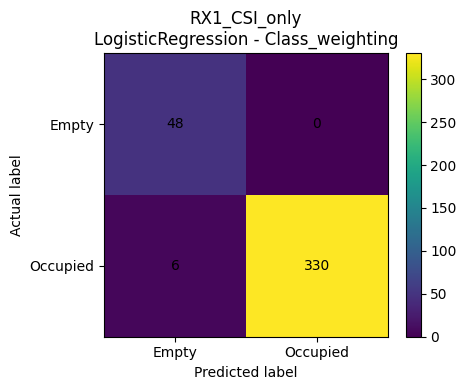

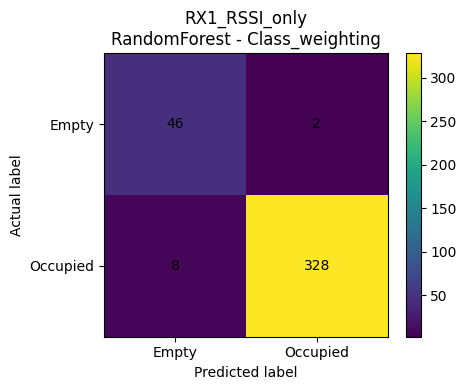

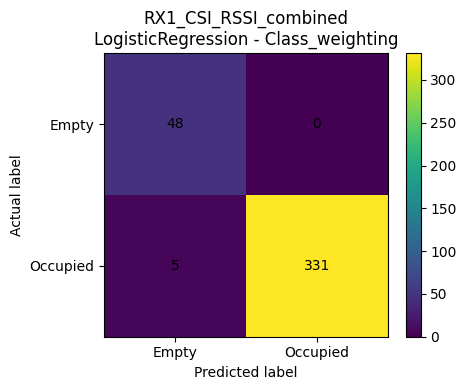

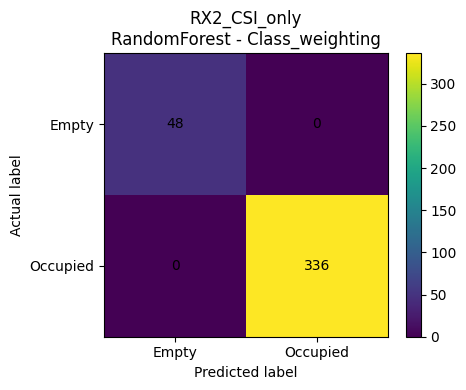

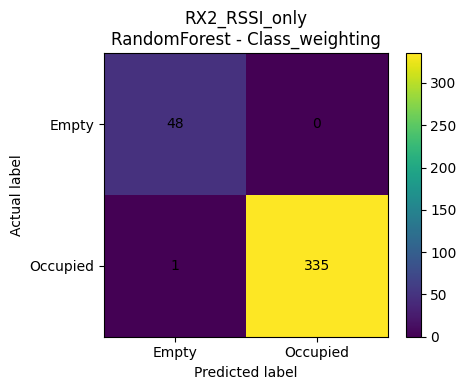

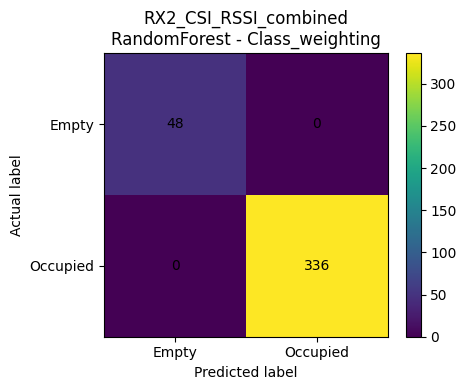

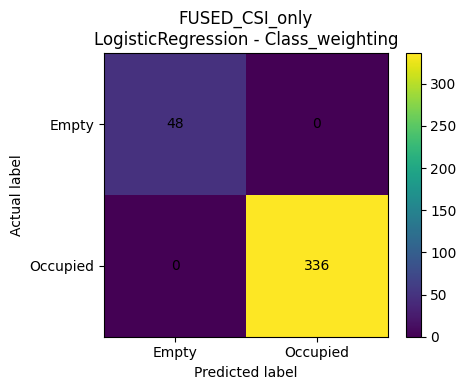

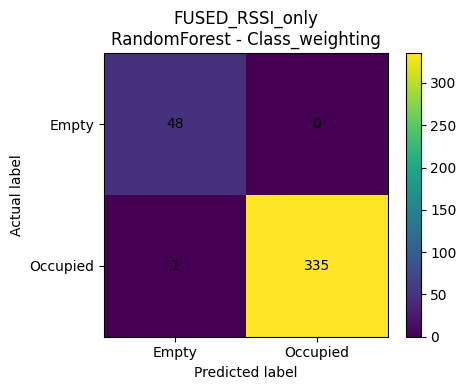

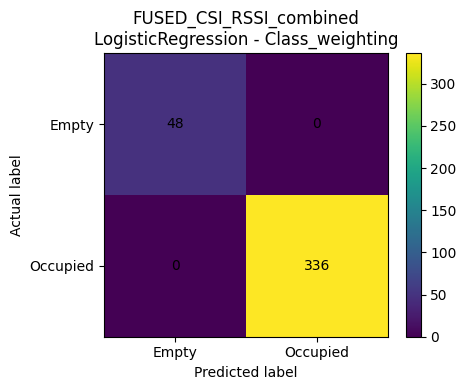

,feature_config,selected_strategy,selected_model,validation_macro_f1,accuracy,precision_occupied,recall_occupied,f1_occupied,macro_f1
3,RX2_CSI_only,Class_weighting,RandomForest,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
6,FUSED_CSI_only,Class_weighting,LogisticRegression,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
8,FUSED_CSI_RSSI_combined,Class_weighting,LogisticRegression,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
5,RX2_CSI_RSSI_combined,Class_weighting,RandomForest,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
4,RX2_RSSI_only,Class_weighting,RandomForest,1.000000,0.997396,1.000000,0.997024,0.998510,0.994100
7,FUSED_RSSI_only,Class_weighting,RandomForest,1.000000,0.997396,1.000000,0.997024,0.998510,0.994100
2,RX1_CSI_RSSI_combined,Class_weighting,LogisticRegression,1.000000,0.986979,1.000000,0.985119,0.992504,0.971499
0,RX1_CSI_only,Class_weighting,LogisticRegression,1.000000,0.984375,1.000000,0.982143,0.990991,0.966084
1,RX1_RSSI_only,Class_weighting,RandomForest,0.955514,0.973958,0.993939,0.976190,0.984985,0.943473


In [ ]:
test_results = []
test_predictions = {}

for feature_name, selected in selected_models.items():
    model = selected["model"]
    feature_cols = selected["feature_cols"]

    X_test = test_df[feature_cols]
    y_test = test_df["label"]
    test_pred = model.predict(X_test)

    metrics = calculate_metrics(y_test, test_pred)
    test_results.append({
        "feature_config": feature_name,
        "selected_strategy": selected["strategy"],
        "selected_model": selected["model_name"],
        "validation_macro_f1": selected["validation_macro_f1"],
        **metrics,
    })
    test_predictions[feature_name] = (y_test.to_numpy(), test_pred)

    report = classification_report(
        y_test, test_pred,
        labels=[0, 1],
        target_names=["Empty", "Occupied"],
        zero_division=0,
        output_dict=True
    )
    pd.DataFrame(report).transpose().to_csv(
        OUTPUT_DIR / f"{feature_name}_classification_report.csv"
    )

    cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5, 4))
    image = ax.imshow(cm)
    ax.set_title(f"{feature_name}\n{selected['model_name']} - {selected['strategy']}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    ax.set_xticks([0, 1], labels=["Empty", "Occupied"])
    ax.set_yticks([0, 1], labels=["Empty", "Occupied"])
    for (i, j), value in np.ndenumerate(cm):
        ax.text(j, i, str(value), ha="center", va="center")
    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{feature_name}_confusion_matrix.png", dpi=250)
    plt.show()
    plt.close(fig)

test_results_df = pd.DataFrame(test_results).sort_values(
    "macro_f1", ascending=False
)
test_results_df.to_csv(OUTPUT_DIR / "final_test_comparison.csv", index=False)
display(test_results_df)


## 11. Direct comparison: RX1 vs RX2 vs fused

The following table focuses on the combined CSI + RSSI + amplitude + packet-count configuration. This is the main comparison for determining whether two-receiver fusion improves binary occupancy detection.


In [ ]:
main_comparison = test_results_df[
    test_results_df["feature_config"].isin([
        "RX1_CSI_RSSI_combined",
        "RX2_CSI_RSSI_combined",
        "FUSED_CSI_RSSI_combined",
    ])
].copy()

display(main_comparison[
    ["feature_config", "selected_model", "selected_strategy",
     "accuracy", "precision_occupied", "recall_occupied", "f1_occupied", "macro_f1"]
].sort_values("feature_config"))

if len(main_comparison) == 3:
    pivot = main_comparison.set_index("feature_config")["macro_f1"]
    print("\\nFused minus RX1 macro-F1:",
          round(pivot["FUSED_CSI_RSSI_combined"] - pivot["RX1_CSI_RSSI_combined"], 4))
    print("Fused minus RX2 macro-F1:",
          round(pivot["FUSED_CSI_RSSI_combined"] - pivot["RX2_CSI_RSSI_combined"], 4))


,feature_config,selected_model,selected_strategy,accuracy,precision_occupied,recall_occupied,f1_occupied,macro_f1
8,FUSED_CSI_RSSI_combined,LogisticRegression,Class_weighting,1.000000,1.0,1.000000,1.000000,1.000000
2,RX1_CSI_RSSI_combined,LogisticRegression,Class_weighting,0.986979,1.0,0.985119,0.992504,0.971499
5,RX2_CSI_RSSI_combined,RandomForest,Class_weighting,1.000000,1.0,1.000000,1.000000,1.000000


\nFused minus RX1 macro-F1: 0.0285
Fused minus RX2 macro-F1: 0.0


In [ ]:

import joblib
import json
from pathlib import Path

# Select the best fused model based on validation performance
selected = selected_models["FUSED_CSI_RSSI_combined"]

best_model = selected["model"]
feature_columns = selected["feature_cols"]

# Package everything needed for future predictions
model_artifact = {
    "model": best_model,
    "feature_columns": feature_columns,
    "model_name": selected["model_name"],
    "balancing_strategy": selected["strategy"],
    "validation_macro_f1": selected["validation_macro_f1"],
    "window_size": WINDOW_SIZE,
    "subcarrier_columns": SUBCARRIER_COLS,
    "label_mapping": {
        0: "Empty",
        1: "Occupied"
    }
}

MODEL_PATH = OUTPUT_DIR / "best_fused_occupancy_model.joblib"

joblib.dump(model_artifact, MODEL_PATH)

print("Model saved successfully!")
print("Model:", selected["model_name"])
print("Features:", len(feature_columns))
print("File:", MODEL_PATH)

# Download the trained model
from google.colab import files
files.download(str(MODEL_PATH))


Model saved successfully!
Model: LogisticRegression
Features: 224
File: /content/RoomB_Analysis/best_fused_occupancy_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd
import numpy as np
import joblib

# Load the saved model
artifact = joblib.load(
    "/content/RoomB_Analysis/best_fused_occupancy_model.joblib"
)

model = artifact["model"]
feature_columns = artifact["feature_columns"]

def predict_new_recording(csv_path):

    df = pd.read_csv(csv_path)

    df["second"] = pd.to_numeric(
        df["second"], errors="coerce"
    )
    df = df.dropna(subset=["second"])

    df["window_start"] = (
        np.floor(df["second"] / WINDOW_SIZE)
        .astype(int) * WINDOW_SIZE
    )

    samples = []

    for start, chunk in df.groupby("window_start"):

        if not (
            safe_bool_series(
                chunk["RX1_record_present"]
            ).any()
            or safe_bool_series(
                chunk["RX2_record_present"]
            ).any()
        ):
            continue

        row = {"window_start_second": int(start)}

        row.update(
            receiver_window_features(chunk, "RX1", start)
        )

        row.update(
            receiver_window_features(chunk, "RX2", start)
        )

        samples.append(row)

    features = pd.DataFrame(samples)

    if features.empty:
        raise ValueError("No valid feature windows found.")

    X = features.reindex(columns=feature_columns)

    predictions = model.predict(X)

    results = pd.DataFrame({
        "window_start_second": features["window_start_second"],
        "predicted_label": predictions,
        "predicted_status": [
            "Empty" if p == 0 else "Occupied"
            for p in predictions
        ]
    })

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X)
        results["empty_probability"] = probabilities[:, 0]
        results["occupied_probability"] = probabilities[:, 1]

    return results


In [ ]:
from google.colab import files
import pandas as pd
import io

# Upload the test CSV file
uploaded = files.upload()

# Read the uploaded CSV
test_file = list(uploaded.keys())[0]
test_df = pd.read_csv(io.BytesIO(uploaded[test_file]))

# Display the data
print("Uploaded file:", test_file)
print("Shape:", test_df.shape)

display(test_df.head())

Saving Fused_window_summary.csv to Fused_window_summary (1).csv
Uploaded file: Fused_window_summary (1).csv
Shape: (120, 141)


,second,RX1_record_present,RX2_record_present,RX1_packet_count,RX1_mean_rssi,RX1_std_rssi,RX1_mean_csi_amplitude,RX1_std_csi_amplitude,RX1_subcarrier_00,RX1_subcarrier_01,...,RX2_subcarrier_54,RX2_subcarrier_55,RX2_subcarrier_56,RX2_subcarrier_57,RX2_subcarrier_58,RX2_subcarrier_59,RX2_subcarrier_60,RX2_subcarrier_61,RX2_subcarrier_62,RX2_subcarrier_63
0,0,True,True,24,-51.0,0.0,10.714955,0.177464,0.0,14.465041,...,13.564313,12.270882,11.235381,9.889710,9.260835,7.959350,9.082747,10.024301,11.878957,13.125229
1,1,True,True,3,-51.0,0.0,10.604461,0.103373,0.0,14.343762,...,13.591222,12.445412,11.152638,10.074132,9.407250,8.834800,9.884185,10.970489,12.958551,14.712272
2,2,True,True,7,-51.0,0.0,10.638207,0.090357,0.0,14.828703,...,13.124523,12.335229,11.157659,9.799940,9.217219,8.783607,9.486051,10.746578,12.575868,13.959935
3,3,True,True,6,-51.0,0.0,10.597206,0.064506,0.0,14.816587,...,13.182361,12.189467,10.863896,9.547016,9.083198,8.402862,9.266437,10.612179,12.491756,14.028373
4,4,True,True,5,-51.0,0.0,10.659842,0.086743,0.0,14.390539,...,13.032682,12.202225,10.931958,9.761744,9.074894,8.441358,9.580775,10.751651,12.683389,14.175728


,window_start_second,predicted_label,predicted_status,empty_probability,occupied_probability,actual_label
0,0,0,Empty,0.999868,0.000132,0
1,5,0,Empty,0.999786,0.000214,0
2,10,0,Empty,0.999889,0.000111,0
3,15,0,Empty,0.999814,0.000186,0
4,20,0,Empty,0.999764,0.000236,0
5,25,0,Empty,0.999662,0.000338,0
6,30,0,Empty,0.999605,0.000395,0
7,35,0,Empty,0.999690,0.000310,0
8,40,0,Empty,0.999865,0.000135,0
9,45,0,Empty,0.999823,0.000177,0


Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

       Empty       1.00      1.00      1.00        24
    Occupied       0.00      0.00      0.00         0

    accuracy                           1.00        24
   macro avg       0.50      0.50      0.50        24
weighted avg       1.00      1.00      1.00        24



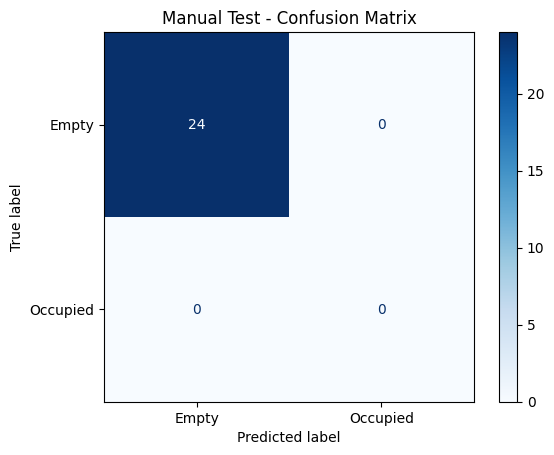

Manual testing completed!


In [ ]:
# these testing is for the empty room
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Input recording
test_csv = "/content/Fused_window_summary (1).csv"

# Set the actual class of this recording
TRUE_LABEL = 0 # 0 = Empty, 1 = Occupied

# Generate predictions
predictions = predict_new_recording(test_csv)

# Add actual labels
predictions["actual_label"] = TRUE_LABEL

# Display predictions
display(predictions)

# Calculate metrics
y_true = predictions["actual_label"]
y_pred = predictions["predicted_label"]

print("Accuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Empty", "Occupied"],
        zero_division=0
    )
)

# Generate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Empty", "Occupied"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Manual Test - Confusion Matrix")
plt.show()

# Save predictions
predictions.to_csv(
    "/content/manual_test_predictions.csv",
    index=False
)

print("Manual testing completed!")

,window_start_second,predicted_label,predicted_status,empty_probability,occupied_probability,actual_label
0,0,1,Occupied,4.726795e-09,1.0,1
1,5,1,Occupied,1.030690e-08,1.0,1
2,10,1,Occupied,3.818359e-09,1.0,1
3,15,1,Occupied,6.789258e-09,1.0,1
4,20,1,Occupied,6.443601e-09,1.0,1
5,25,1,Occupied,5.640825e-09,1.0,1
6,30,1,Occupied,3.537427e-08,1.0,1
7,35,1,Occupied,3.886551e-08,1.0,1
8,40,1,Occupied,4.217319e-08,1.0,1
9,45,1,Occupied,2.897442e-08,1.0,1


Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

       Empty       0.00      0.00      0.00         0
    Occupied       1.00      1.00      1.00        24

    accuracy                           1.00        24
   macro avg       0.50      0.50      0.50        24
weighted avg       1.00      1.00      1.00        24



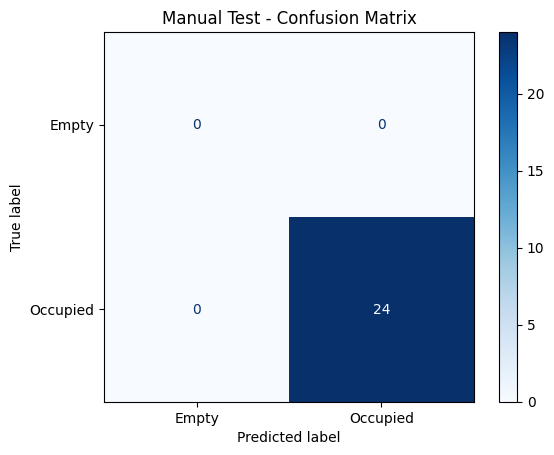

Manual testing completed!


In [ ]:

# these testing is for the occupied room
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Input recording
test_csv = "/content/Fused_window_summary.csv"

# Set the actual class of this recording
TRUE_LABEL = 1  # 0 = Empty, 1 = Occupied

# Generate predictions
predictions = predict_new_recording(test_csv)

# Add actual labels
predictions["actual_label"] = TRUE_LABEL

# Display predictions
display(predictions)

# Calculate metrics
y_true = predictions["actual_label"]
y_pred = predictions["predicted_label"]

print("Accuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Empty", "Occupied"],
        zero_division=0
    )
)

# Generate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Empty", "Occupied"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Manual Test - Confusion Matrix")
plt.show()

# Save predictions
predictions.to_csv(
    "/content/manual_test_predictions.csv",
    index=False
)

print("Manual testing completed!")

## 12. Export analysis outputs

The output folder contains:
- `all_receiver_features.csv`
- `validation_model_comparison.csv`
- `final_test_comparison.csv`
- Per-configuration classification reports
- Per-configuration confusion matrix images

A ZIP of the results is created for download.


In [ ]:
import shutil

results_zip_base = OUTPUT_DIR / "RoomB_Analysis_Results"
results_zip = shutil.make_archive(
    str(results_zip_base),
    "zip",
    root_dir=OUTPUT_DIR
)

print("Analysis completed.")
print("Results folder:", OUTPUT_DIR)
print("Results ZIP:", results_zip)

try:
    from google.colab import files
    files.download(results_zip)
except ImportError:
    print("Download the ZIP from the output path above.")


Analysis completed.
Results folder: /content/RoomB_Analysis
Results ZIP: /content/RoomB_Analysis/RoomB_Analysis_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "macro_f1",
    ascending=False
)

results_df.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False
)

NameError: name 'results' is not defined

In [ ]:
import os

for root, dirs, files_list in os.walk(OUTPUT_DIR):
    for filename in files_list:
        print(os.path.join(root, filename))

/content/RoomB_Analysis/RX2_CSI_RSSI_combined_classification_report.csv
/content/RoomB_Analysis/RoomB_Analysis_Results.zip
/content/RoomB_Analysis/final_test_comparison.csv
/content/RoomB_Analysis/RX2_CSI_only_confusion_matrix.png
/content/RoomB_Analysis/RX2_CSI_RSSI_combined_confusion_matrix.png
/content/RoomB_Analysis/FUSED_CSI_RSSI_combined_confusion_matrix.png
/content/RoomB_Analysis/FUSED_CSI_RSSI_combined_classification_report.csv
/content/RoomB_Analysis/RX1_CSI_RSSI_combined_confusion_matrix.png
/content/RoomB_Analysis/best_fused_occupancy_model.joblib
/content/RoomB_Analysis/RX2_CSI_only_classification_report.csv
/content/RoomB_Analysis/validation_model_comparison.csv
/content/RoomB_Analysis/RX1_RSSI_only_confusion_matrix.png
/content/RoomB_Analysis/FUSED_RSSI_only_classification_report.csv
/content/RoomB_Analysis/all_receiver_features.csv
/content/RoomB_Analysis/RX2_RSSI_only_classification_report.csv
/content/RoomB_Analysis/FUSED_RSSI_only_confusion_matrix.png
/content/RoomB_

In [ ]:
from google.colab import files

files.download(
    "/content/RoomB_Analysis/final_test_comparison.csv"
)

files.download(
    "/content/RoomB_Analysis/validation_model_comparison.csv"
)

files.download(
    "/content/RoomB_Analysis/RoomB_Analysis_Results.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Interpretation and reporting checklist

When interpreting the results, report:
1. Test accuracy, occupied precision/recall, occupied F1, and macro-F1.
2. Which model and balancing strategy were selected using validation data.
3. Whether fused features improve over RX1-only and RX2-only features.
4. The confusion matrices, especially false-empty and false-occupied errors.
5. The number of feature windows and recording repetitions in each split.
6. The number of missing/unmatched receiver windows and how they were handled.

**Research caution:** The same repetition number is held out across all scenarios, which avoids splitting windows from a repetition across train and test. However, if repetitions were collected in a fixed order or under changing environmental conditions, discuss this limitation. For stronger evidence, consider repeated grouped cross-validation by repetition or a second independent recording session.

**Scope:** This is binary occupancy detection. Since C2–C8 are all labelled occupied, this experiment cannot estimate the number of people. A people-counting model requires a separate ground-truth count for each scenario/repetition.
